# IMAGE CLASSIFIER


In [1]:
from functools import partial
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
import torchvision
from torchvision import datasets,transforms
from torchvision.transforms import ToTensor
import numpy as np
import matplotlib.pyplot as plt

print(f"PyTorch version: {torch.__version__}\ntorchvision version: {torchvision.__version__}")

PyTorch version: 2.9.1+cu130
torchvision version: 0.24.1+cu130


In [2]:
torch.cuda.is_available()
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


### DATA LOADING

In [7]:
from torch.utils.data import DataLoader
from torchvision import transforms, datasets
from torch.utils.data import random_split
from collections import Counter

images_dir = "dataset/images_dataset"

# Load without transforms for now
images_dataset = datasets.ImageFolder(root=images_dir, transform=None)

# Print classes
print("Classes found:", images_dataset.classes)
print("Class-to-index mapping:", images_dataset.class_to_idx)

# Split dataset
total_size = len(images_dataset)
val_size = int(0.20 * total_size)
train_size = total_size - val_size

train_dataset, val_dataset = random_split(images_dataset, [train_size, val_size])

print("Train size:", len(train_dataset))
print("Val size:", len(val_dataset))

# ---------- CLASS COUNTING (ADDED) ----------
def count_classes(split_dataset, full_dataset, class_names):
    counter = Counter()
    for idx in split_dataset.indices:
        _, label = full_dataset.samples[idx]
        counter[label] += 1

    for class_idx, name in enumerate(class_names):
        print(f"{name}: {counter[class_idx]} images")

print("\n--- TRAIN CLASS DISTRIBUTION ---")
count_classes(train_dataset, images_dataset, images_dataset.classes)

print("\n--- VALIDATION CLASS DISTRIBUTION ---")
count_classes(val_dataset, images_dataset, images_dataset.classes)
# -------------------------------------------

# Valores estándar de normalización para modelos pre-entrenados en ImageNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# ----------- TRANSFORMACIONES CORREGIDAS -----------

train_transform = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD) 
])

val_transform = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Apply transforms to the underlying ImageFolder
train_dataset.dataset.transform = train_transform
val_dataset.dataset.transform = val_transform


# ----------- DATALOADERS -----------
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=4,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

Classes found: ['forgetable', 'memorable']
Class-to-index mapping: {'forgetable': 0, 'memorable': 1}
Train size: 55356
Val size: 13839

--- TRAIN CLASS DISTRIBUTION ---
forgetable: 17550 images
memorable: 37806 images

--- VALIDATION CLASS DISTRIBUTION ---
forgetable: 4343 images
memorable: 9496 images


In [4]:
from PIL import Image
import os

def find_bad_images(root):
    bad = []
    for folder, _, files in os.walk(root):
        for file in files:
            if file.lower().endswith(("jpg","jpeg","png","bmp","gif")):
                path = os.path.join(folder, file)
                try:
                    img = Image.open(path)
                    img.verify()
                except:
                    bad.append(path)
    return bad

""" 
bad_images = find_bad_images("dataset/images_dataset")
print("Bad images:")
for b in bad_images:
    print(b)
"""

' \nbad_images = find_bad_images("dataset/images_dataset")\nprint("Bad images:")\nfor b in bad_images:\n    print(b)\n'

## TRANSFER LEARNING


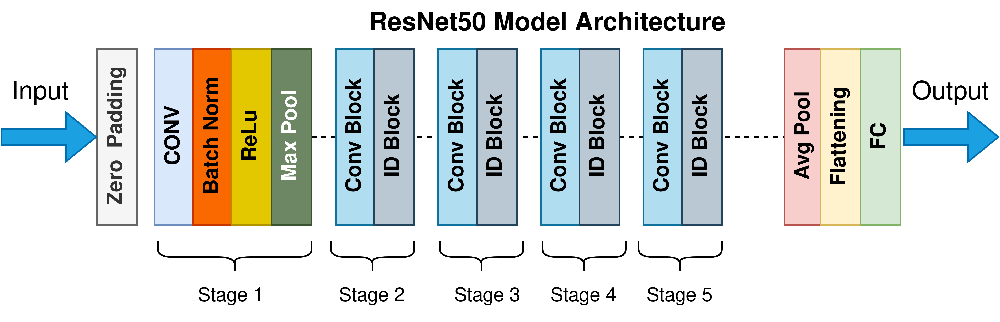

In [5]:
from torchvision.models import resnet50, ResNet50_Weights

num_classes = 2

model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)
model.fc = torch.nn.Linear(model.fc.in_features, num_classes)
model = model.to("cuda" if torch.cuda.is_available() else "cpu")

In [6]:
""""
no backpropagation

no weight updates

the convolutional backbone becomes a feature extractor
"""

for param in model.parameters():
    param.requires_grad = False

# but keep the last layer trainable
for param in model.fc.parameters():
    param.requires_grad = True


In [7]:
criterion = torch.nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.fc.parameters(),   # only train classifier, unless you unfreeze entire model
    lr=1e-4,
    weight_decay=1e-5
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.3,
    patience=2
)


In [8]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0
        self.early_stop = False
        self.best_state = None

    def step(self, val_loss, model):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            # Save the best model weights
            self.best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1

        if self.counter >= self.patience:
            self.early_stop = True

In [9]:
# Example structure for the missing function:
def validate_model(model, val_loader, criterion, device="cuda"):
    model.eval() # Set model to evaluation mode
    total_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    with torch.no_grad(): # Disable gradient calculation
        for inputs, labels in val_loader:
            # Move data to the correct device
            inputs = inputs.to(device)
            labels = labels.to(device)

            # Forward pass
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * inputs.size(0)

            # Calculate accuracy
            _, predicted = torch.max(outputs.data, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

    avg_loss = total_loss / total_samples
    accuracy = correct_predictions / total_samples

    return avg_loss, accuracy

In [10]:
import matplotlib.pyplot as plt
import time
from sklearn.metrics import f1_score

print(time.time())
# Listas para almacenar las métricas
train_accuracies = []
val_accuracies = []
train_f1_scores = []
val_f1_scores = []
train_losses = []
val_losses = []

def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, epochs=1, patience=5):

    early = EarlyStopping(patience=patience)

    model.train()
    total_batches = len(train_loader)

    for epoch in range(epochs):
        running_loss = 0.0
        correct = 0
        total = 0
        start_time_epoch = time.time()

        print(f"Epoch [{epoch+1}/{epochs}] Starting...")

        for batch_idx, (images, labels) in enumerate(train_loader):
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            preds = torch.argmax(outputs, dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
            batch_accuracy = correct / total

            print(f"  Batch [{batch_idx+1}/{total_batches}], "
                f"Loss: {loss.item():.4f}, "
                f"Batch Accuracy: {batch_accuracy:.4f}")

        # ---- end of epoch metrics ----
        epoch_loss = running_loss / total_batches
        epoch_accuracy = correct / total

        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_accuracy)

        epoch_time = time.time() - start_time_epoch
        print(f"End of Epoch {epoch+1}: Loss: {epoch_loss:.4f}, "
                f"Accuracy: {epoch_accuracy:.4f}, Time: {epoch_time:.2f} sec")

        # ---- validation ----
        val_loss, val_accuracy = validate_model(model, val_loader, criterion)
        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)

        # scheduler step
        scheduler.step(val_loss)

        # F1 score (last batch)
        epoch_f1_score = f1_score(labels.cpu().numpy(), preds.cpu().numpy(), average='macro')
        train_f1_scores.append(epoch_f1_score)

        # ---- EARLY STOPPING CHECK ----
        early.step(val_loss, model)
        if early.early_stop:
            print(f"\n⏹️ Early stopping triggered at epoch {epoch+1}")
            print(f"Best Validation Loss: {early.best_loss:.4f}")
            # Restore best weights:
            model.load_state_dict(early.best_state)
            break

    return model


1764557367.3703187


In [11]:
trained_model = train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    epochs= 20, # 3 for fast run 100 for full training
    patience=5
)


Epoch [1/20] Starting...
  Batch [1/2201], Loss: 0.6162, Batch Accuracy: 0.7812
  Batch [2/2201], Loss: 0.5464, Batch Accuracy: 0.8125
  Batch [3/2201], Loss: 0.6428, Batch Accuracy: 0.7708
  Batch [4/2201], Loss: 0.5641, Batch Accuracy: 0.7734
  Batch [5/2201], Loss: 0.6166, Batch Accuracy: 0.7625
  Batch [6/2201], Loss: 0.5029, Batch Accuracy: 0.7708
  Batch [7/2201], Loss: 0.5816, Batch Accuracy: 0.7679
  Batch [8/2201], Loss: 0.6700, Batch Accuracy: 0.7578
  Batch [9/2201], Loss: 0.6111, Batch Accuracy: 0.7535
  Batch [10/2201], Loss: 0.4191, Batch Accuracy: 0.7656
  Batch [11/2201], Loss: 0.6591, Batch Accuracy: 0.7585
  Batch [12/2201], Loss: 0.4671, Batch Accuracy: 0.7630
  Batch [13/2201], Loss: 0.5289, Batch Accuracy: 0.7644
  Batch [14/2201], Loss: 0.4886, Batch Accuracy: 0.7656
  Batch [15/2201], Loss: 0.4734, Batch Accuracy: 0.7688
  Batch [16/2201], Loss: 0.4396, Batch Accuracy: 0.7734
  Batch [17/2201], Loss: 0.6477, Batch Accuracy: 0.7684
  Batch [18/2201], Loss: 0.5954,

#### GUARDADO

In [12]:
import torch

# 1. Define the filename
PATH = "modelos guardados/resnet50_finetunedV2.pth"

# 2. Save the state dictionary
torch.save(trained_model.state_dict(), PATH)

#### CARGAR EL MODELO DE NUEVO

In [1]:
import torch
from torchvision.models import resnet50, ResNet50_Weights

# 1. Define the parameters you used during training
num_classes = 2
PATH = "modelos guardados/resnet50_finetunedV2.pth" # Replace with your actual path

# 2. Re-instantiate the base model with the exact same weights argument
loaded_model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)

# 3. Re-apply the exact same final layer modification
# This ensures the new layer matches the one whose weights you saved.
loaded_model.fc = torch.nn.Linear(loaded_model.fc.in_features, num_classes)

# 4. Load the trained weights from the file
loaded_model.load_state_dict(torch.load(PATH))

# 5. Move the model to the correct device and set to evaluation mode
device = "cuda" if torch.cuda.is_available() else "cpu"
loaded_model = loaded_model.to(device)
loaded_model.eval() # IMPORTANT for inference!

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

### 5.1 MATRIZ DE CONFUCION

In [5]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns # Recomendado para visualización


def get_predictions_and_labels(model, data_loader, device):
    """
    Realiza predicciones en el conjunto de datos y recopila
    las etiquetas reales y predichas.
    """
    all_labels = []
    all_preds = []
    model.eval() # Poner el modelo en modo evaluación
    
    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            
            outputs = model(inputs)
            # Obtener el índice de la clase con la probabilidad más alta
            _, predicted = torch.max(outputs, 1)
            
            # Guardar etiquetas reales y predichas
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(predicted.cpu().numpy())
            
    return np.array(all_labels), np.array(all_preds)

# Definición del dispositivo
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [8]:
from torch.utils.data import DataLoader
from torchvision import transforms, datasets
from torch.utils.data import random_split
from collections import Counter

images_dir = "dataset/images_dataset"

# Load without transforms for now
images_dataset = datasets.ImageFolder(root=images_dir, transform=None)

# Print classes
print("Classes found:", images_dataset.classes)
print("Class-to-index mapping:", images_dataset.class_to_idx)

# Split dataset
total_size = len(images_dataset)
val_size = int(0.20 * total_size)
train_size = total_size - val_size

train_dataset, val_dataset = random_split(images_dataset, [train_size, val_size])

print("Train size:", len(train_dataset))
print("Val size:", len(val_dataset))

# ---------- CLASS COUNTING (ADDED) ----------
def count_classes(split_dataset, full_dataset, class_names):
    counter = Counter()
    for idx in split_dataset.indices:
        _, label = full_dataset.samples[idx]
        counter[label] += 1

    for class_idx, name in enumerate(class_names):
        print(f"{name}: {counter[class_idx]} images")

print("\n--- TRAIN CLASS DISTRIBUTION ---")
count_classes(train_dataset, images_dataset, images_dataset.classes)

print("\n--- VALIDATION CLASS DISTRIBUTION ---")
count_classes(val_dataset, images_dataset, images_dataset.classes)
# -------------------------------------------

# Valores estándar de normalización para modelos pre-entrenados en ImageNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# ----------- TRANSFORMACIONES CORREGIDAS -----------

train_transform = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD) 
])

val_transform = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Apply transforms to the underlying ImageFolder
train_dataset.dataset.transform = train_transform
val_dataset.dataset.transform = val_transform


# ----------- DATALOADERS -----------
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=4,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

Classes found: ['forgetable', 'memorable']
Class-to-index mapping: {'forgetable': 0, 'memorable': 1}
Train size: 55356
Val size: 13839

--- TRAIN CLASS DISTRIBUTION ---
forgetable: 17602 images
memorable: 37754 images

--- VALIDATION CLASS DISTRIBUTION ---
forgetable: 4291 images
memorable: 9548 images


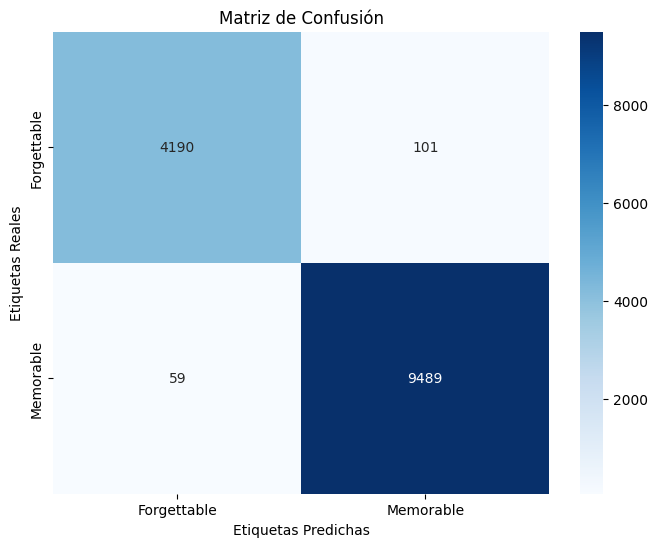


Matriz de Confusión (etiquetas reales vs predichas):
 [[4190  101]
 [  59 9489]]


In [9]:
# --- Asume que 'loaded_model' y 'test_loader' (o 'val_loader') están definidos ---
# Ejemplo: si usas tu cargador de validación
# test_loader = val_loader 

# 1. Obtener las etiquetas reales y las predicciones
true_labels, predictions = get_predictions_and_labels(loaded_model, val_loader, device)

# 2. Definir las clases
class_names = ['Forgettable', 'Memorable']

# 3. Calcular la matriz de confusión 
cm = confusion_matrix(true_labels, predictions)

# 4. Visualizar la matriz de confusión usando Seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, 
    annot=True,        # Mostrar los números en cada celda
    fmt='d',           # Formato decimal para los númerosa
    cmap='Blues',      # Mapa de color
    xticklabels=class_names, 
    yticklabels=class_names
)
plt.title('Matriz de Confusión')
plt.ylabel('Etiquetas Reales')
plt.xlabel('Etiquetas Predichas')
plt.show()

print("\nMatriz de Confusión (etiquetas reales vs predichas):\n", cm)

In [10]:
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torchvision.transforms as transforms
import torch.nn.functional as F

# 1. Define the Inference Transform
# This must match your validation transform + Normalization
inference_transform = transforms.Compose([
    transforms.Resize((512, 512)), # Your specific 512x512 resolution
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def predict_and_show_image(model, image_path, device="cuda"):
    """
    Reads an image, transforms it for the model (512x512 + Norm),
    predicts the class, and displays the ORIGINAL image with the result.
    """
    
    # --- A. Load Image ---
    try:
        # We load the image and convert to RGB to ensure 3 channels
        original_image = Image.open(image_path).convert('RGB')
    except FileNotFoundError:
        print(f"Error: Could not find image at {image_path}")
        return

    # --- B. Prepare for Model (Transform) ---
    # Apply transforms: Resize -> Tensor -> Normalize
    image_tensor = inference_transform(original_image)
    # Add batch dimension (1, 3, 512, 512) and move to GPU/CPU
    image_tensor = image_tensor.unsqueeze(0).to(device)

    # --- C. Make Prediction ---
    model.eval() # Ensure model is in eval mode
    with torch.no_grad():
        outputs = model(image_tensor)
        
        # Calculate probabilities
        probs = F.softmax(outputs, dim=1)
        
        # Get the winner
        max_prob, predicted_idx = torch.max(probs, 1)
        
        # Map index to class name
        class_names = ['Forgettable', 'Memorable']
        predicted_class = class_names[predicted_idx.item()]
        confidence = max_prob.item()

    # --- D. Visualize ---
    plt.figure(figsize=(6, 6))
    
    # We display 'original_image' because it looks natural. 
    # (The tensor is normalized and would look dark/distorted if displayed)
    plt.imshow(original_image)
    
    plt.title(f"Prediction: {predicted_class}\nConfidence: {confidence:.2%}")
    plt.axis('off')
    plt.show()

In [11]:
# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Ensure your model is on the correct device
loaded_model = loaded_model.to(device)


In [12]:
import os

def predict_all_in_folder(model, folder_path, device="cuda"):
    """
    Loops through every image in the folder and calls your predict_and_show_image().
    Shows each prediction with the image.
    """
    
    supported_ext = ('.png', '.jpg', '.jpeg', '.bmp', '.webp')

    # Loop through files
    for filename in os.listdir(folder_path):
        if filename.lower().endswith(supported_ext):
            img_path = os.path.join(folder_path, filename)
            print(f"\n--- Predicting: {filename} ---")
            predict_and_show_image(model, img_path, device)


### VISUAL TESTING


--- Predicting: 001ddffdc17b24e4.jpg ---


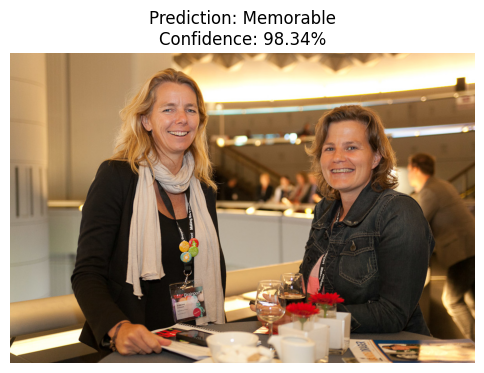


--- Predicting: 01f37f9a2a897d15.jpg ---


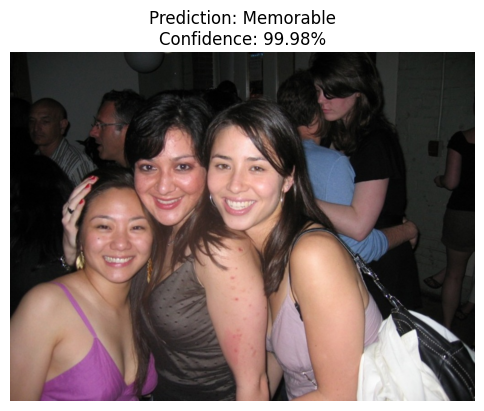


--- Predicting: 024345fc7b1eaca3.jpg ---


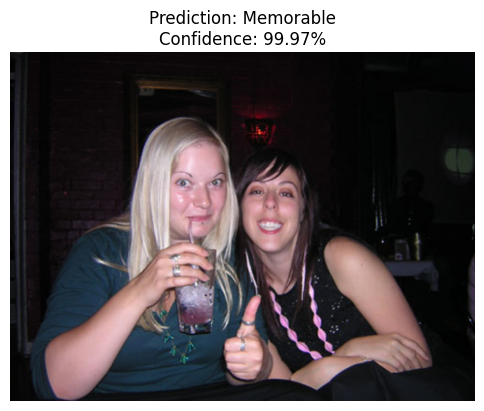


--- Predicting: 02a25d35f4f3011d.jpg ---


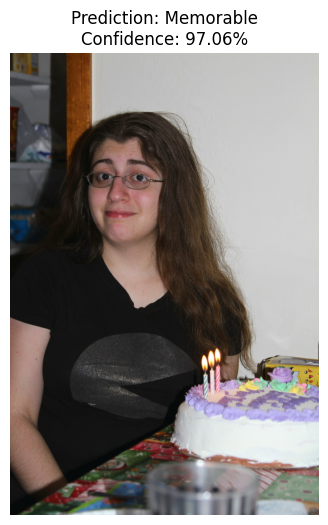


--- Predicting: 25e20e33-75fb-4c29-b6e2-e024493cf5db.jpg ---


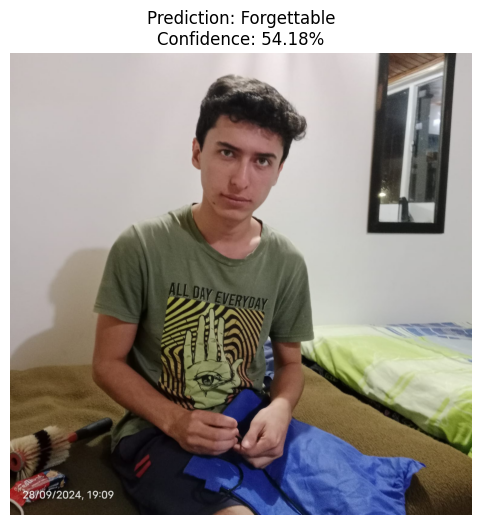


--- Predicting: ad0cdeee-29e4-4197-b04f-72d87850261e.jpg ---


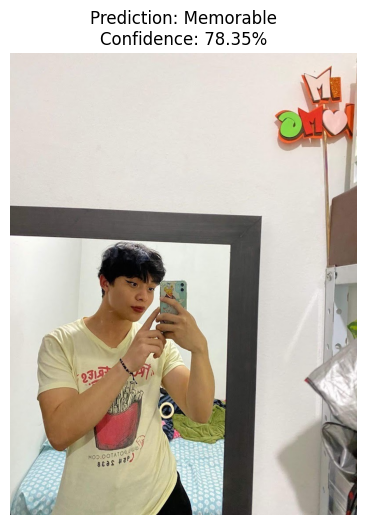


--- Predicting: artworks-fPpuEYc97yU35rqI-Na2yfg-t500x500.png ---


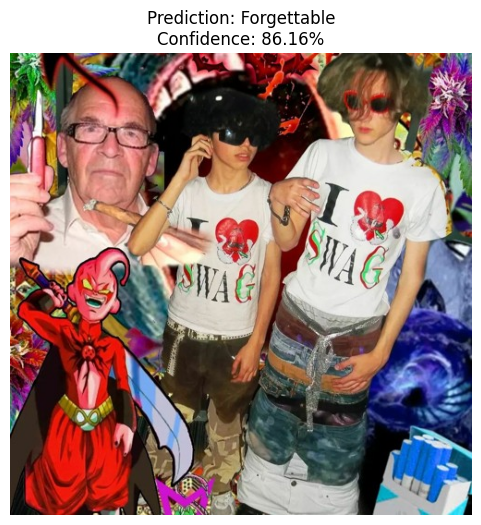


--- Predicting: Dios_plan.png ---


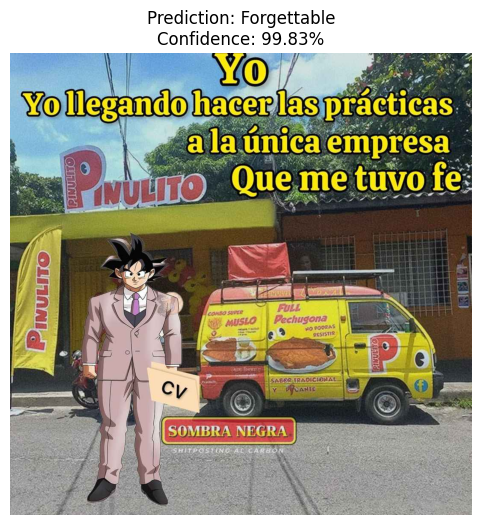


--- Predicting: eaf3ae599208c2f38db76993d96e1343.jpg ---


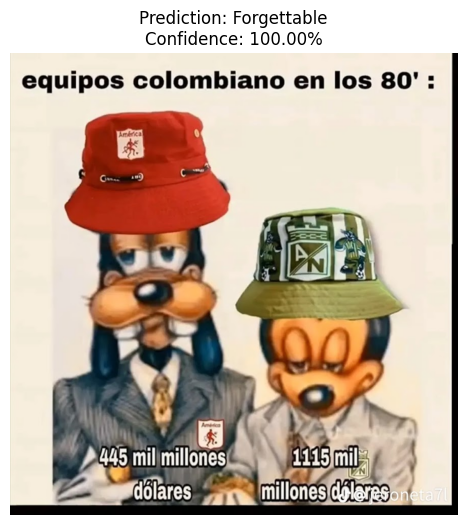


--- Predicting: FOTO.jpg ---


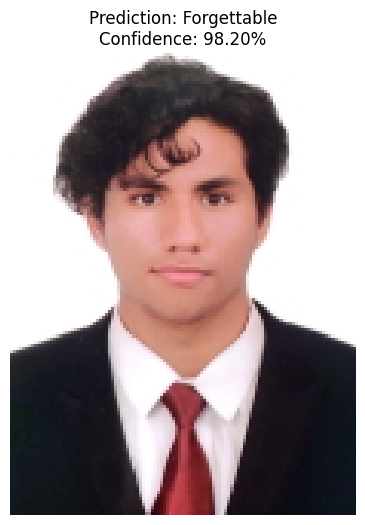


--- Predicting: hq720 (1).jpg ---


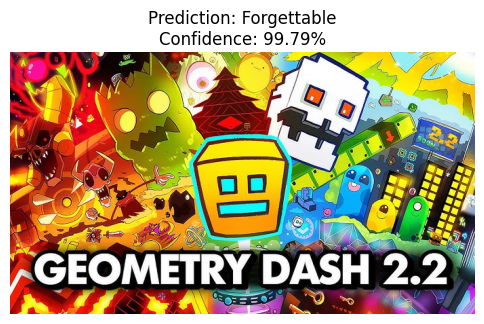


--- Predicting: hq720.jpg ---


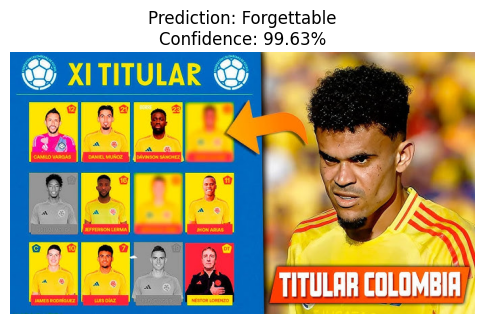


--- Predicting: image.png ---


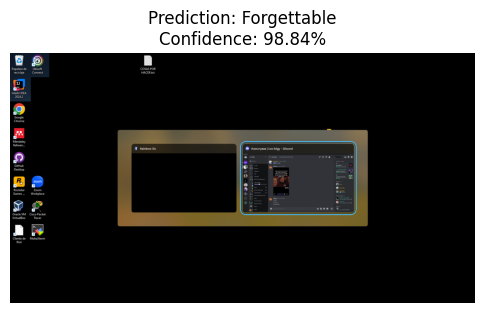


--- Predicting: images.jpg ---


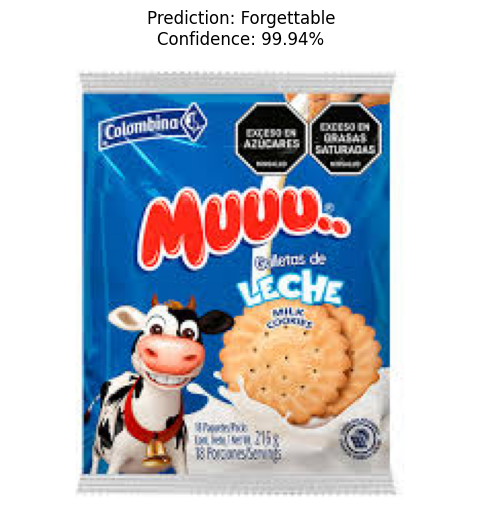


--- Predicting: images.png ---


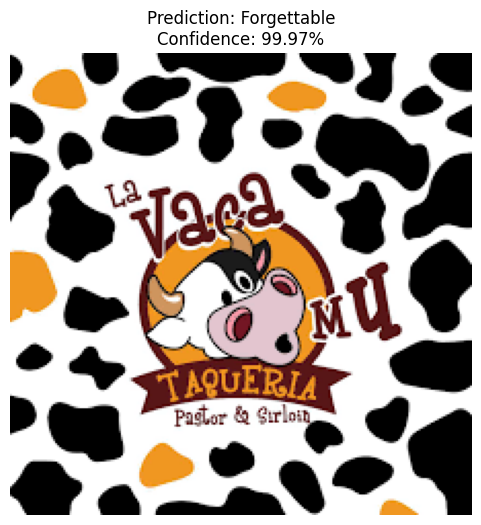


--- Predicting: IMG-20240924-WA0031.jpg ---


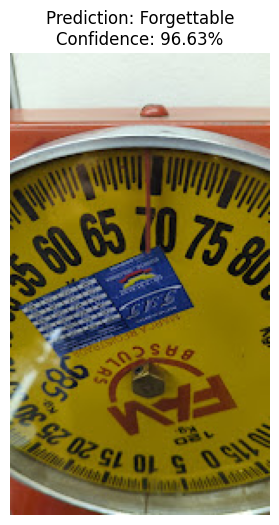


--- Predicting: IMG-20240924-WA0054.jpg ---


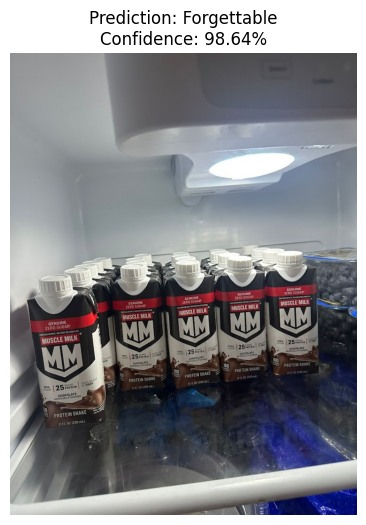


--- Predicting: IMG-20240925-WA0001.jpg ---


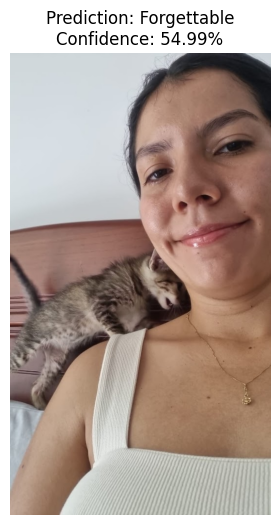


--- Predicting: IMG-20240927-WA0031.jpg ---


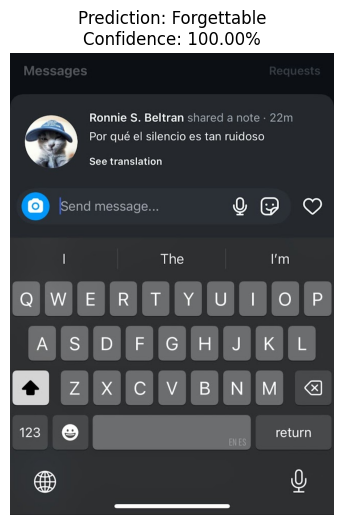


--- Predicting: IMG-20240928-WA0004.jpg ---


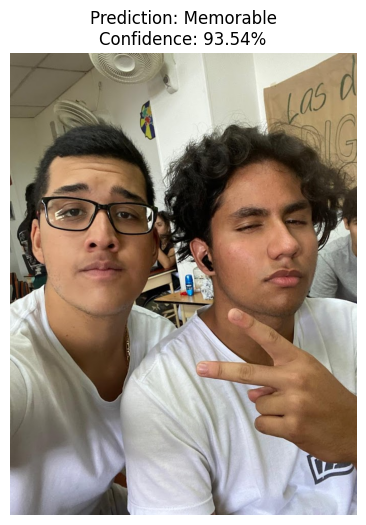


--- Predicting: IMG-20240929-WA0003.jpg ---


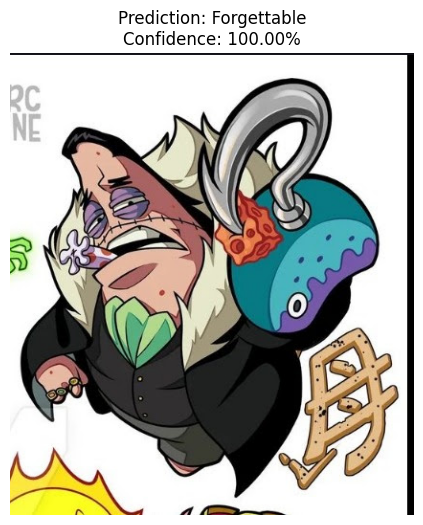


--- Predicting: IMG-20240930-WA0013.jpg ---


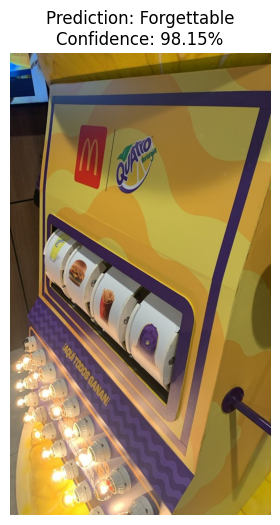


--- Predicting: IMG-20250703-WA0089.jpg ---


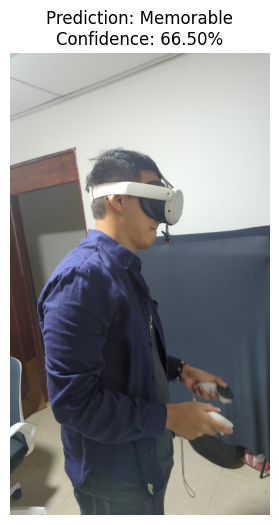


--- Predicting: IMG_20240916_164640.jpg ---


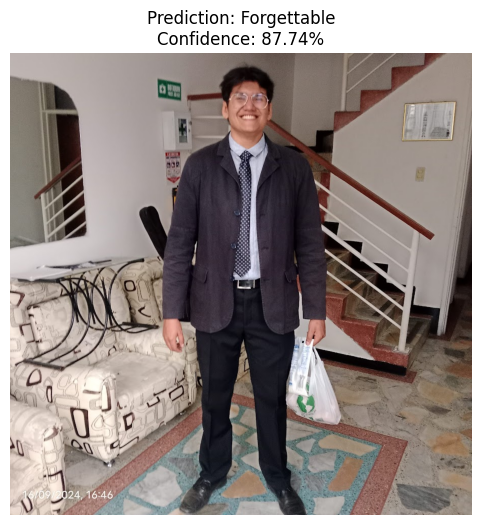


--- Predicting: maxresdefault.jpg ---


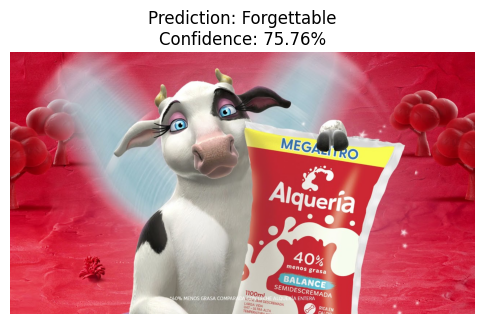


--- Predicting: piscila.jpg ---


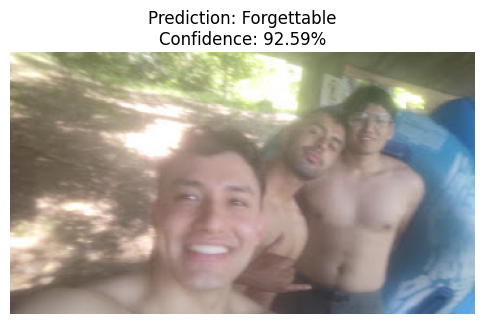


--- Predicting: POLLO.jpg ---


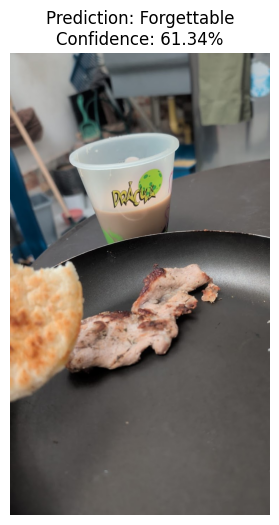


--- Predicting: RobloxScreenShot20240827_201410636.png ---


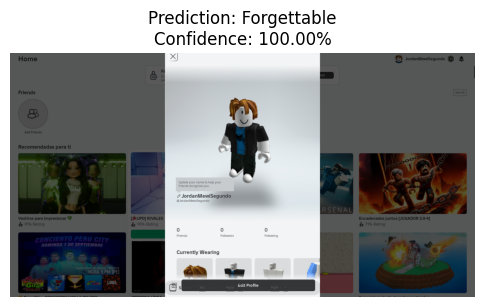


--- Predicting: Screenshot 2025-10-04 140855.png ---


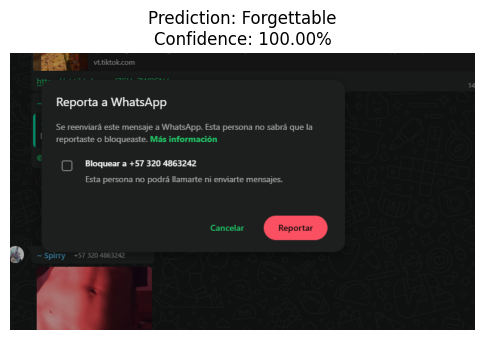


--- Predicting: Screenshot 2025-10-05 113651.png ---


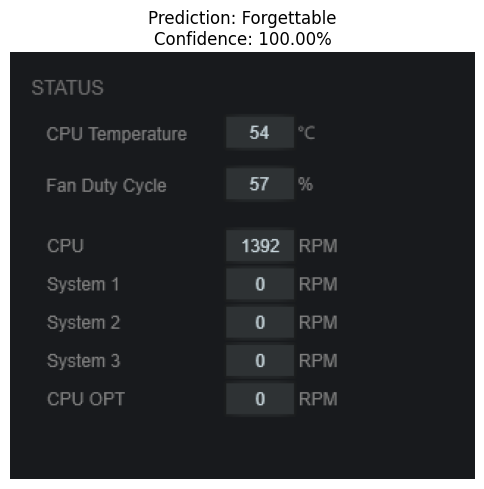


--- Predicting: Screenshot 2025-10-05 113846.png ---


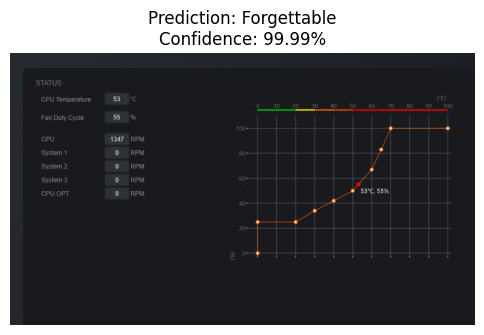


--- Predicting: Screenshot 2025-10-06 173601.png ---


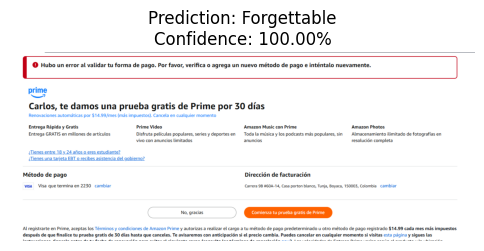


--- Predicting: Screenshot 2025-10-06 181858.png ---


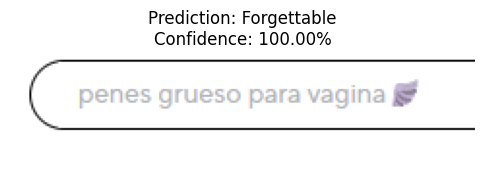


--- Predicting: Screenshot 2025-10-07 073822.png ---


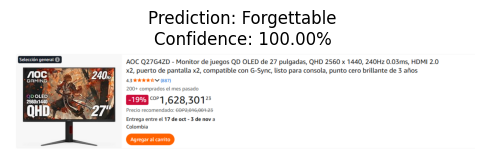


--- Predicting: Screenshot 2025-10-07 075027.png ---


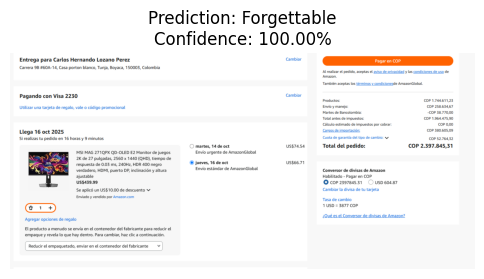


--- Predicting: Screenshot 2025-10-07 075210.png ---


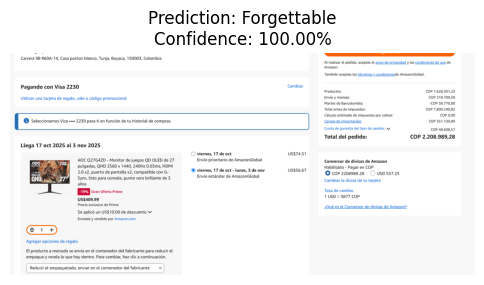


--- Predicting: Screenshot 2025-10-07 081205.png ---


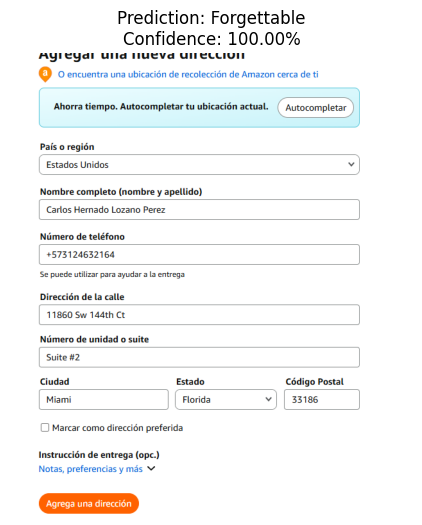


--- Predicting: Screenshot 2025-10-07 082023.png ---


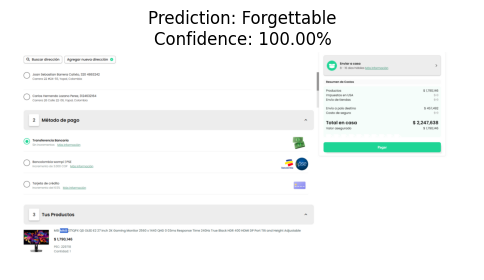


--- Predicting: Screenshot 2025-10-07 082036.png ---


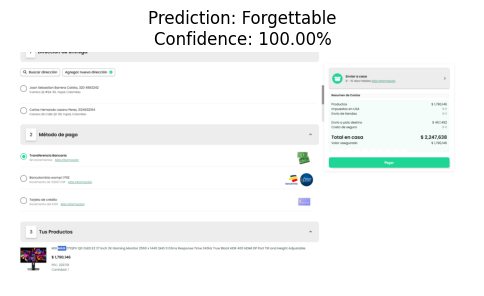


--- Predicting: Screenshot 2025-10-07 082456.png ---


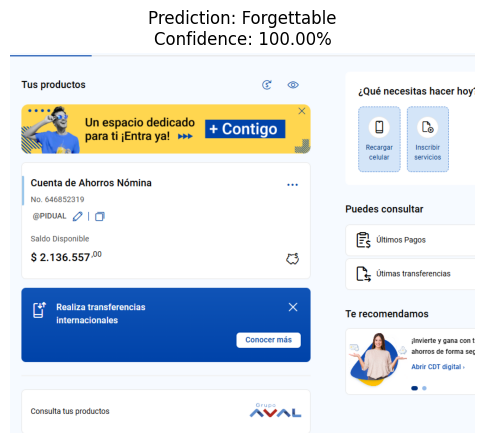


--- Predicting: Screenshot 2025-10-07 082957.png ---


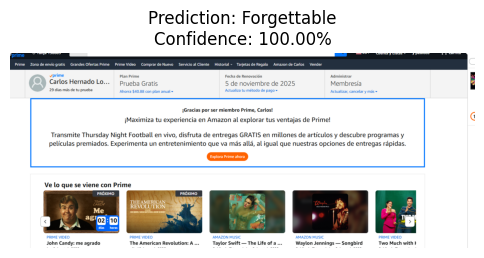


--- Predicting: Screenshot 2025-10-07 175349.png ---


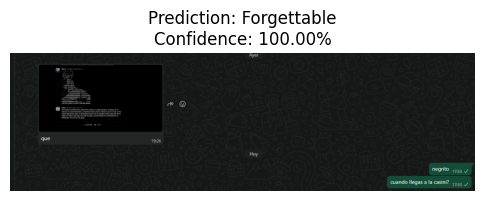


--- Predicting: Screenshot 2025-10-08 183655.png ---


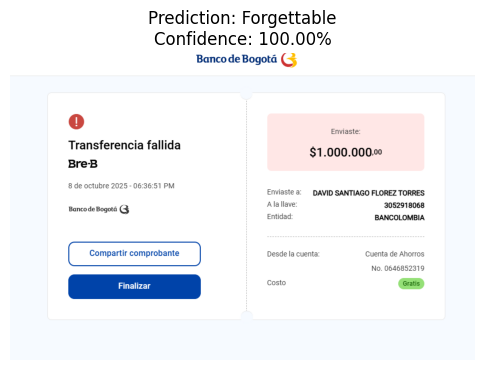


--- Predicting: Screenshot 2025-10-08 183817.png ---


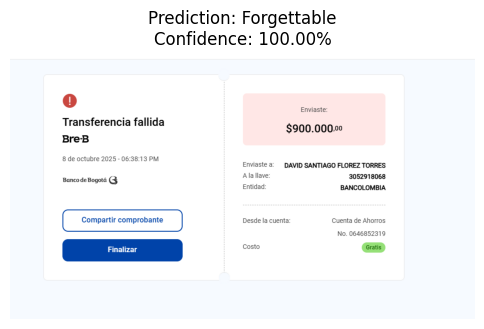


--- Predicting: Screenshot 2025-10-10 222052.png ---


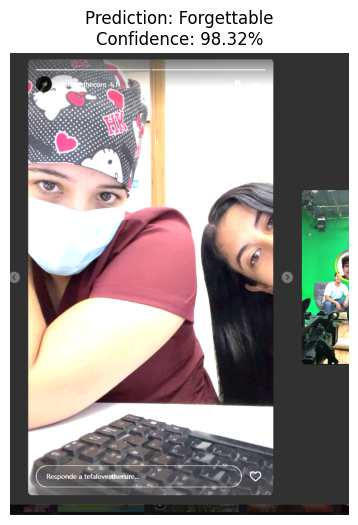


--- Predicting: Screenshot 2025-10-19 103552.png ---


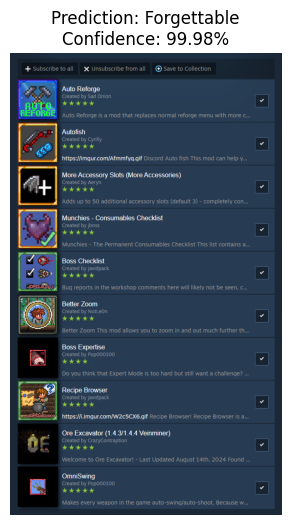


--- Predicting: Screenshot 2025-10-19 105258.png ---


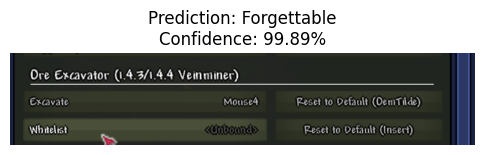


--- Predicting: Screenshot 2025-10-20 210412.png ---


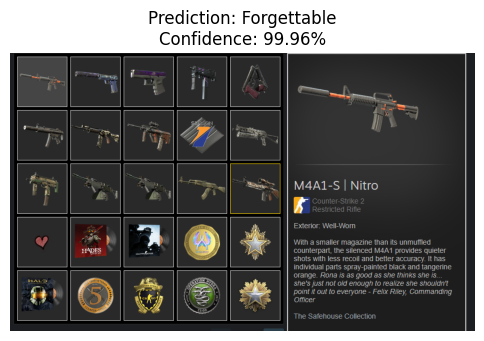


--- Predicting: Screenshot 2025-10-20 210427.png ---


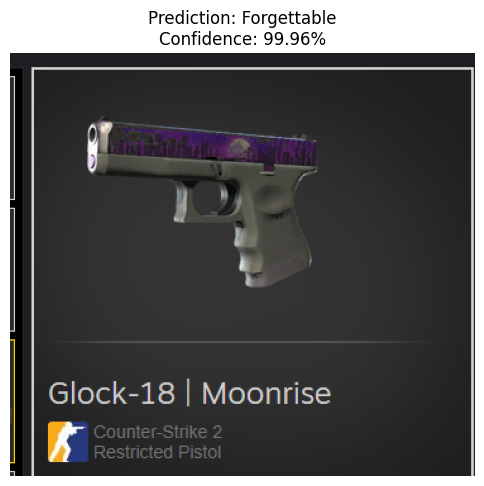


--- Predicting: Screenshot 2025-10-20 210433.png ---


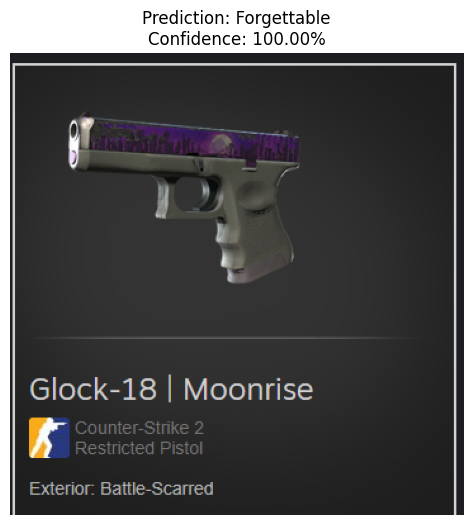


--- Predicting: Screenshot 2025-10-20 210441.png ---


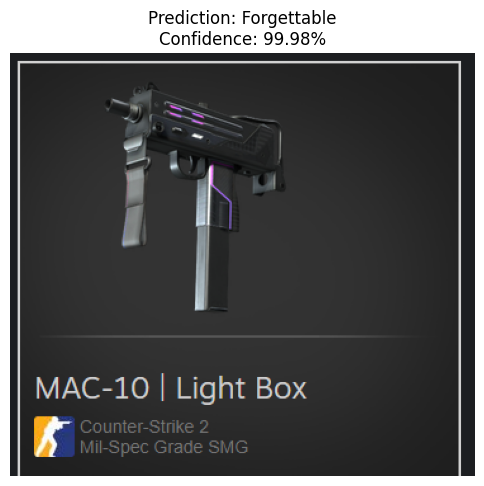


--- Predicting: Screenshot 2025-10-24 190334.png ---


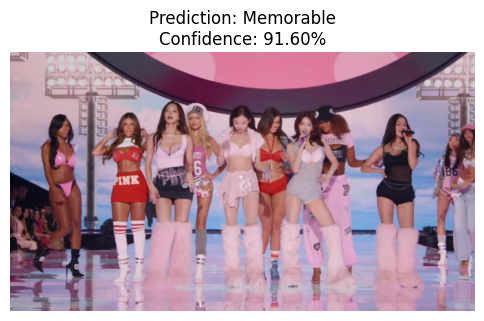


--- Predicting: Screenshot 2025-10-24 190516.png ---


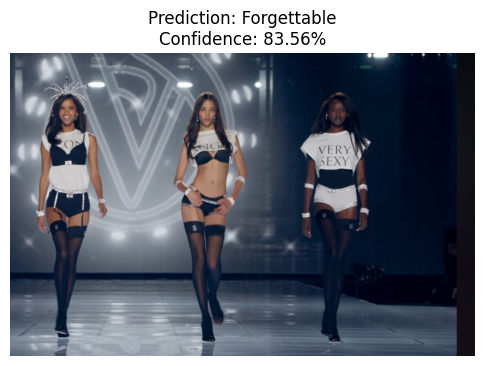


--- Predicting: Screenshot 2025-10-24 204350.png ---


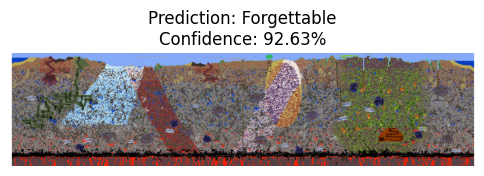


--- Predicting: Screenshot 2025-10-26 171202.png ---


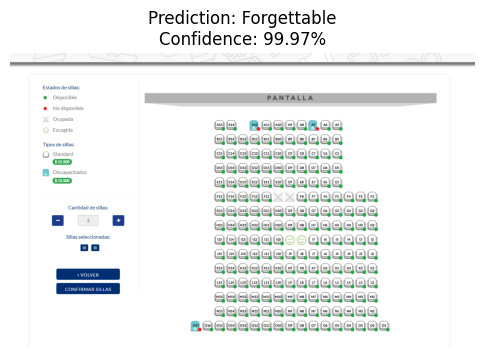


--- Predicting: Screenshot 2025-10-27 200219.png ---


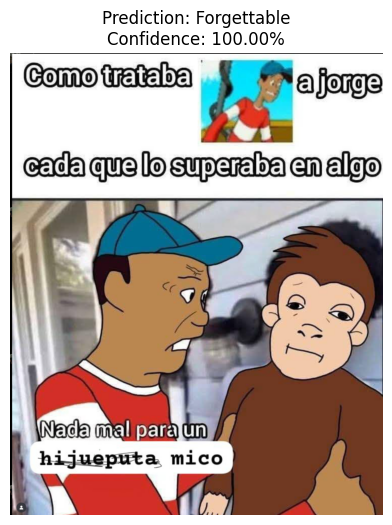


--- Predicting: Screenshot 2025-10-27 203817.png ---


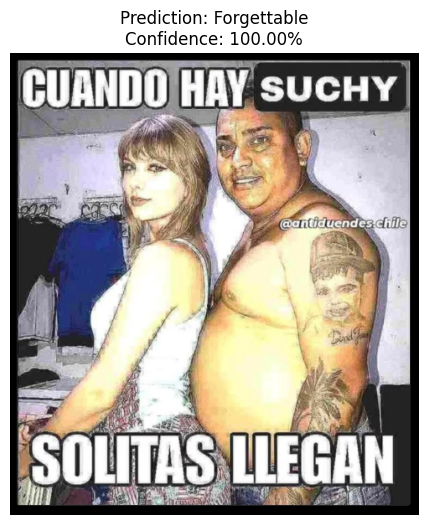


--- Predicting: Screenshot 2025-10-28 194620.png ---


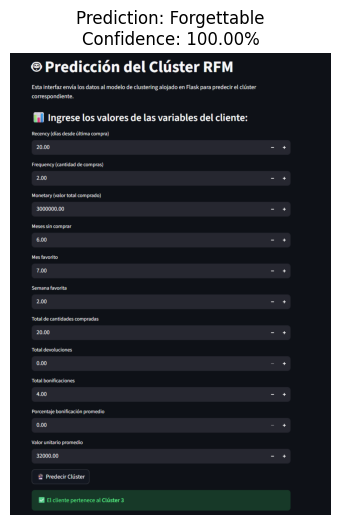


--- Predicting: Screenshot 2025-11-02 230233.png ---


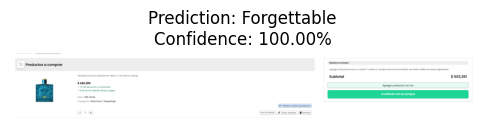


--- Predicting: Screenshot 2025-11-03 113637.png ---


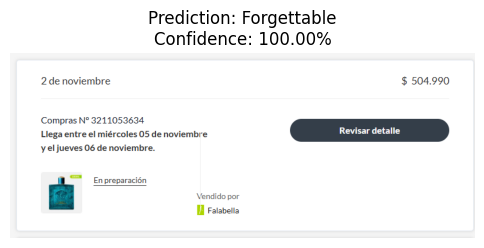


--- Predicting: Screenshot 2025-11-04 223939.png ---


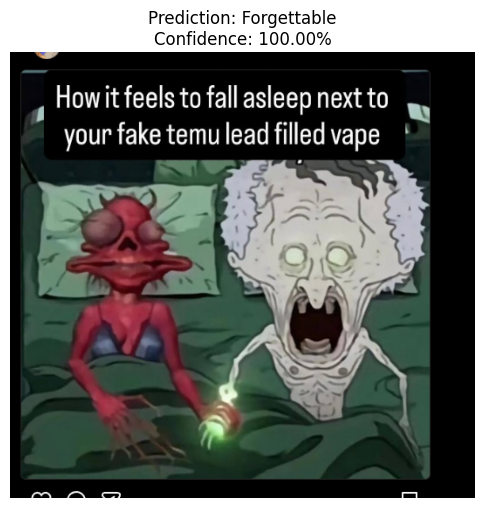


--- Predicting: Screenshot 2025-11-05 202138.png ---


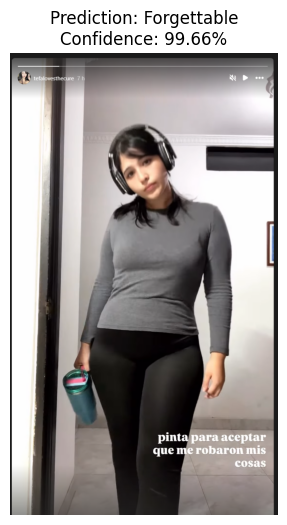


--- Predicting: Screenshot 2025-11-08 170802.png ---


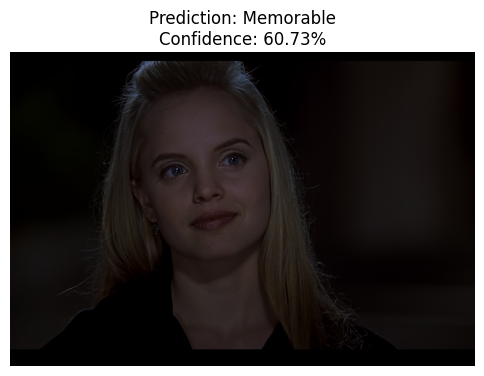


--- Predicting: Screenshot 2025-11-09 105315.png ---


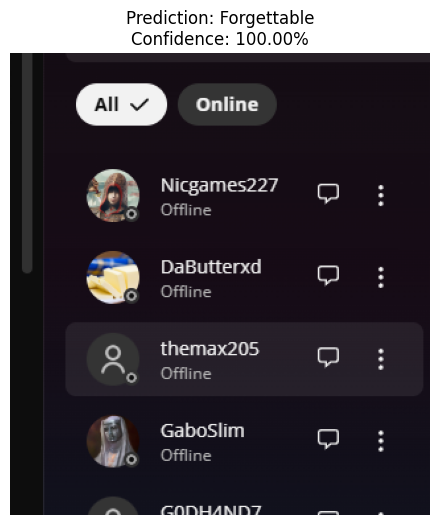


--- Predicting: Screenshot 2025-11-09 141211.png ---


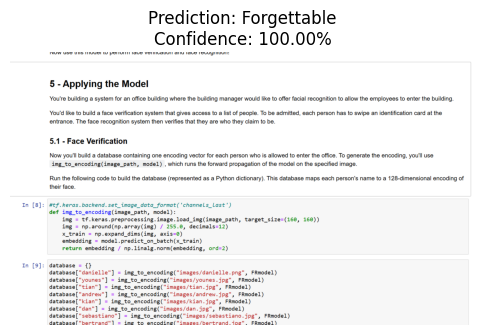


--- Predicting: Screenshot 2025-11-09 210412.png ---


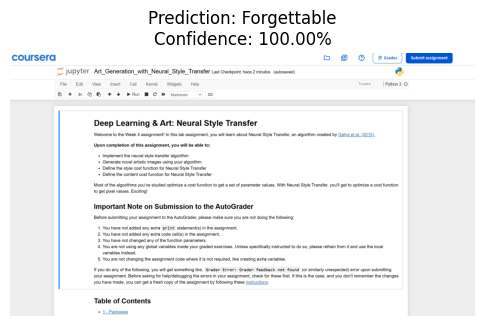


--- Predicting: Screenshot 2025-11-10 100053.png ---


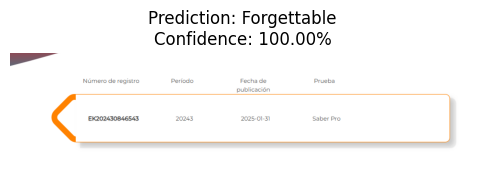


--- Predicting: Screenshot 2025-11-10 110448.png ---


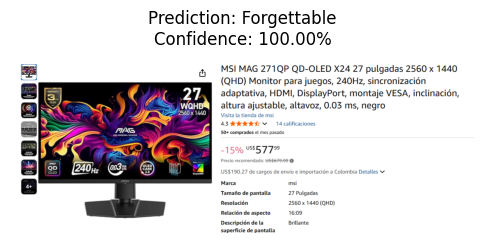


--- Predicting: Screenshot 2025-11-14 163737.png ---


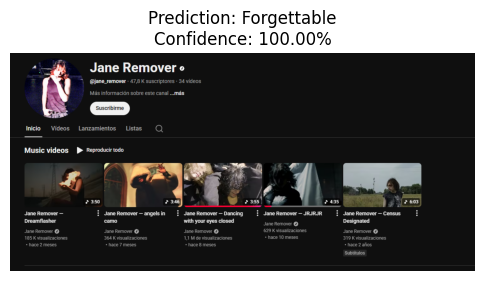


--- Predicting: Screenshot 2025-11-16 131337.png ---


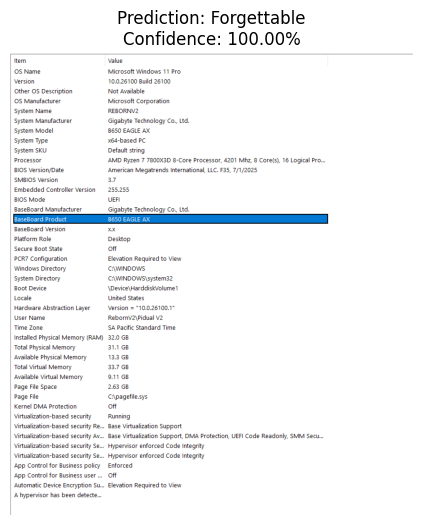


--- Predicting: Screenshot 2025-11-16 132356.png ---


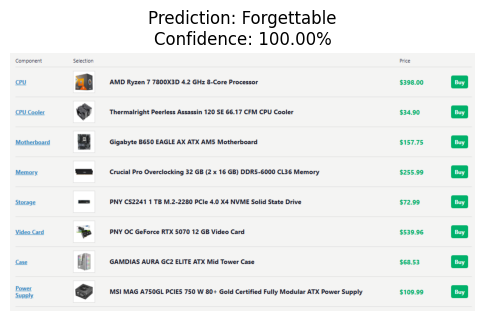


--- Predicting: Screenshot 2025-11-16 143007.png ---


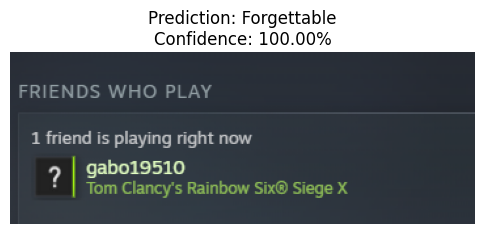


--- Predicting: Screenshot 2025-11-16 154237.png ---


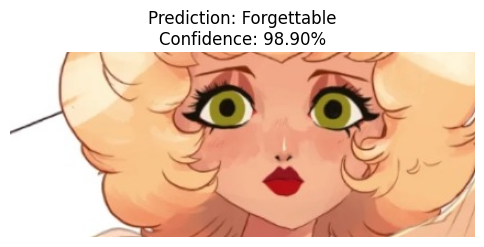


--- Predicting: Screenshot 2025-11-16 154312.png ---


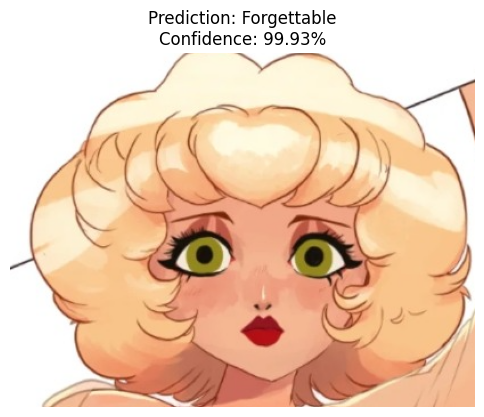


--- Predicting: Screenshot 2025-11-16 201708.png ---


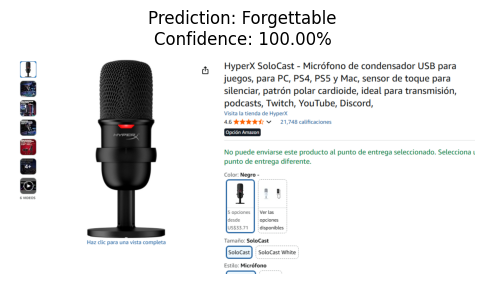


--- Predicting: Screenshot 2025-11-16 203211.png ---


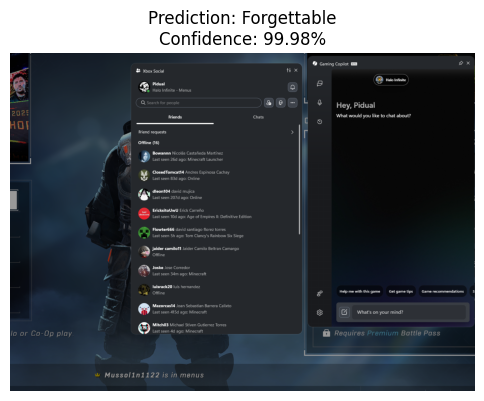


--- Predicting: Screenshot 2025-11-16 203441.png ---


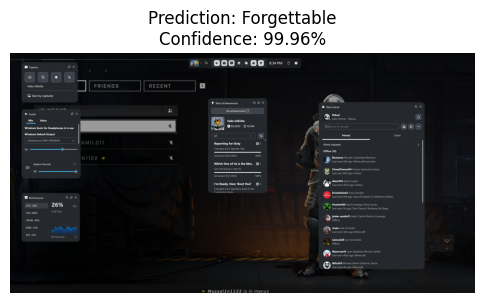


--- Predicting: Screenshot 2025-11-16 203617.png ---


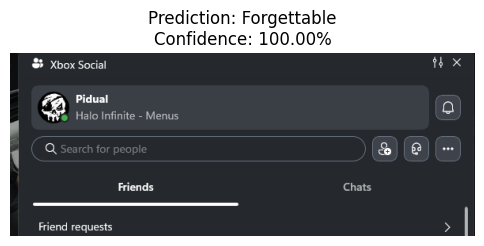


--- Predicting: Screenshot 2025-11-17 083801.png ---


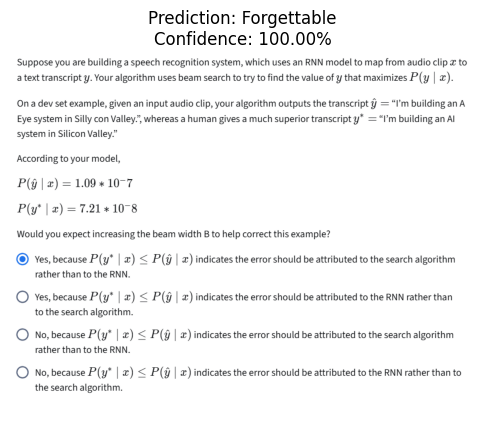


--- Predicting: Screenshot 2025-11-17 083839.png ---


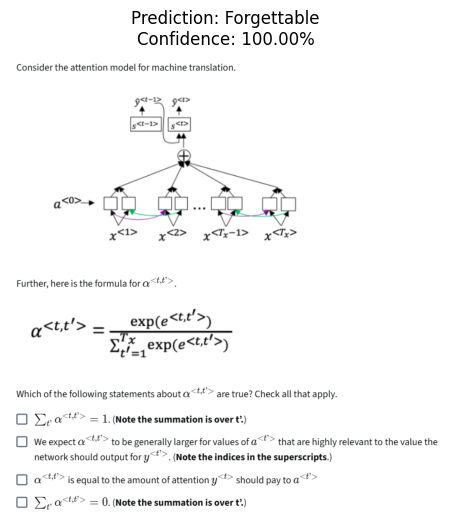


--- Predicting: Screenshot 2025-11-17 084028.png ---


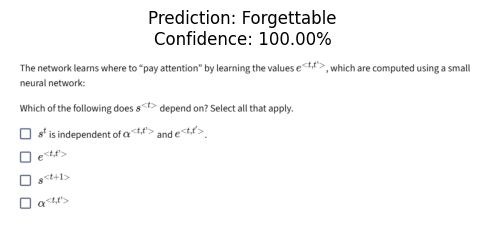


--- Predicting: Screenshot 2025-11-21 190004.png ---


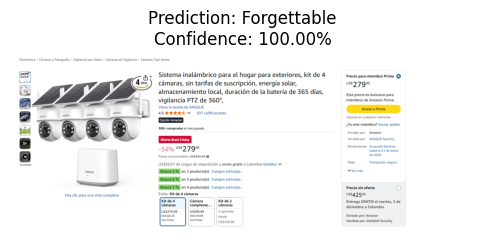


--- Predicting: Screenshot 2025-11-21 214128.png ---


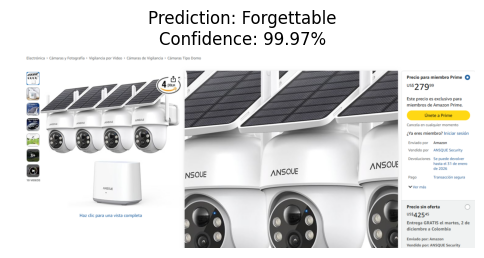


--- Predicting: Screenshot 2025-11-21 214132.png ---


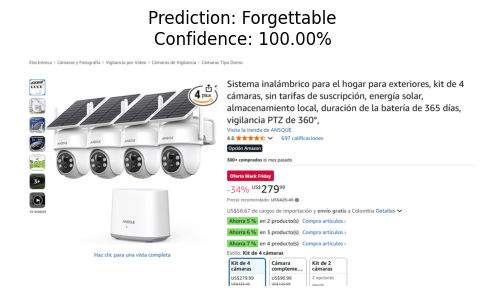


--- Predicting: Screenshot 2025-11-22 014605.png ---


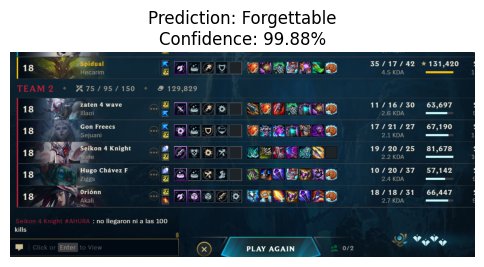


--- Predicting: Screenshot 2025-11-23 000457.png ---


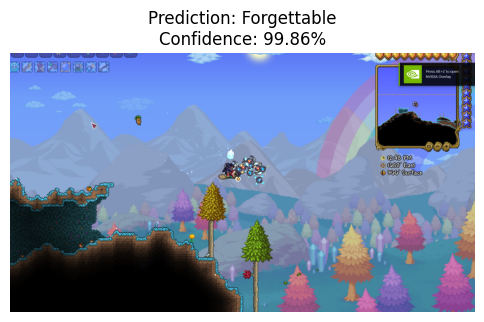


--- Predicting: Screenshot 2025-11-23 110909.png ---


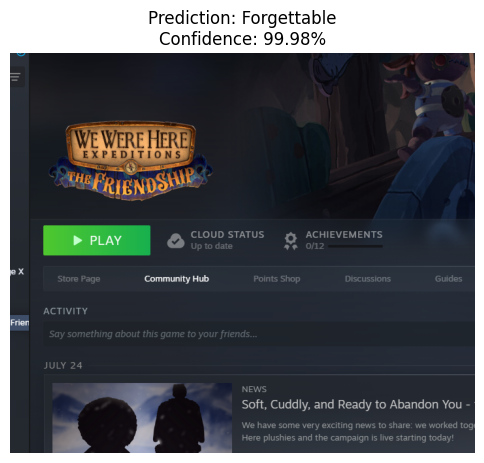


--- Predicting: Screenshot 2025-11-25 191333.png ---


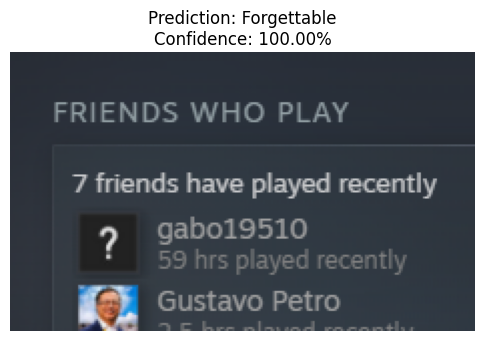


--- Predicting: Screenshot 2025-11-30 134828.png ---


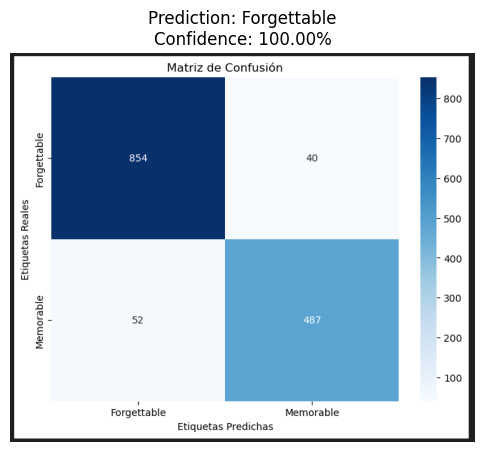


--- Predicting: Screenshot_20240928_155128.jpg ---


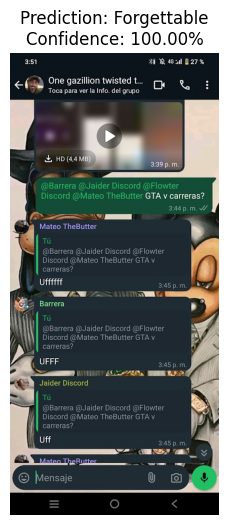


--- Predicting: SSSSS.jpg ---


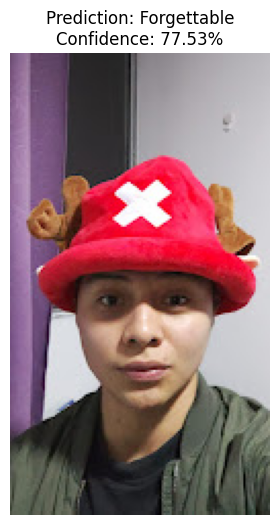


--- Predicting: TEST MEMORABLE.jpg ---


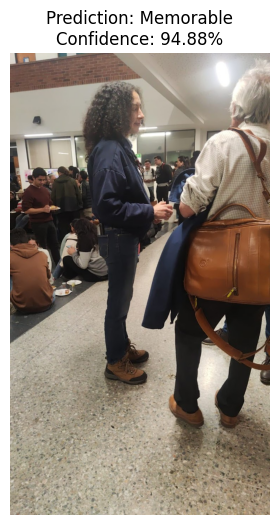


--- Predicting: TEST MIKU.jpg ---


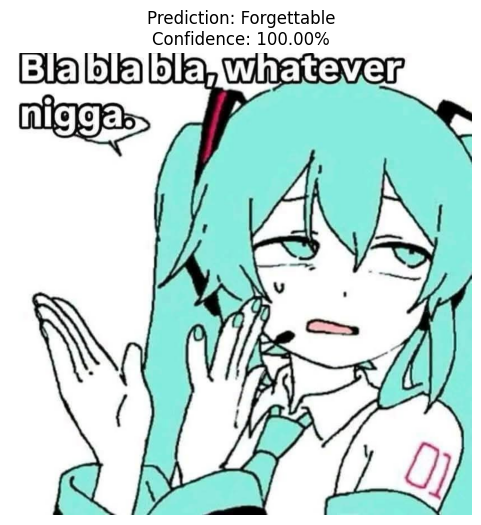

In [13]:
predict_all_in_folder(loaded_model, r"dataset\visual_testing", device)

.<br>.<br>.<br>.<br>.<br>.<br>.<br>.<br>.<br>.<br>.<br>.<br>.<br>.




We love and respect
alex puertas



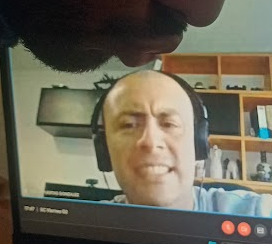

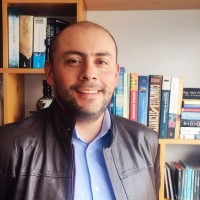

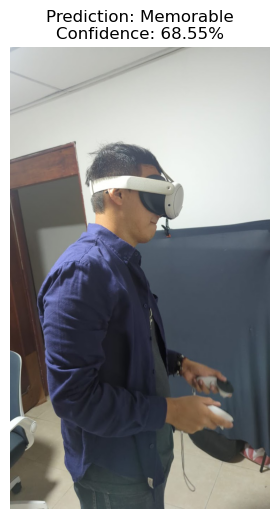

In [20]:
predict_and_show_image(loaded_model, 'dataset/visual_testing/IMG-20250703-WA0089.jpg', device)

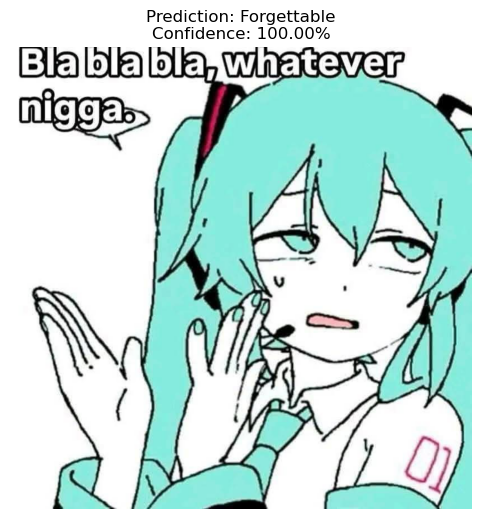

In [21]:
predict_and_show_image(loaded_model, 'dataset/visual_testing/TEST MIKU.jpg', device)

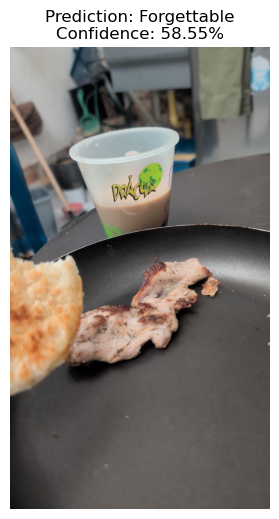

In [22]:
predict_and_show_image(loaded_model, 'dataset/visual_testing/POLLO.jpg', device)

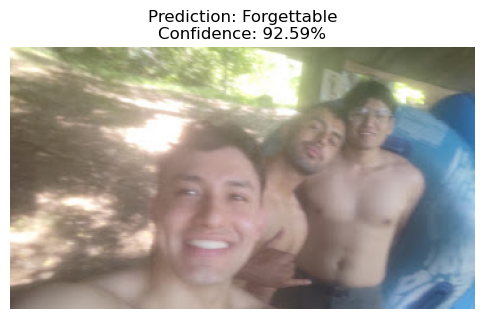

In [23]:
predict_and_show_image(loaded_model, 'dataset/visual_testing/piscila.jpg', device)

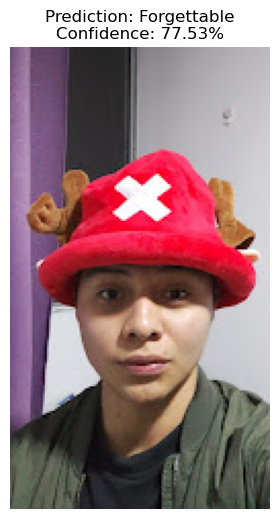

In [24]:
predict_and_show_image(loaded_model, 'dataset/visual_testing/SSSSS.jpg', device)

# ONNX 

In [4]:
torch.cuda.is_available()

True

In [1]:
import torch
from torchvision.models import resnet50, ResNet50_Weights

# 1. Define the parameters you used during training
num_classes = 2
PATH = "modelos guardados/resnet50_finetunedV2.pth" # Replace with your actual path

# 2. Re-instantiate the base model with the exact same weights argument
loaded_model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)

# 3. Re-apply the exact same final layer modification
# This ensures the new layer matches the one whose weights you saved.
loaded_model.fc = torch.nn.Linear(loaded_model.fc.in_features, num_classes)

# 4. Load the trained weights from the file
loaded_model.load_state_dict(torch.load(PATH))

# 5. Move the model to the correct device and set to evaluation mode
device = "cuda" if torch.cuda.is_available() else "cpu"
loaded_model = loaded_model.to(device)
loaded_model.eval() # IMPORTANT for inference!

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [ ]:
import torch

# Ensure model is on CPU and in eval mode
model = loaded_model.cpu()
model.eval()

# Create dummy input matching your input size
dummy_input = torch.randn(1, 3, 512, 512)

# Export to ONNX
torch.onnx.export(
    model,
    dummy_input,
    "modelos guardados/resnet50_classifier.onnx",
    input_names=["image"],
    output_names=["prediction"],
    dynamic_axes={
        "image": {0: "batch_size"},
        "prediction": {0: "batch_size"}
    },
    opset_version=14
)

print("✅ Model exported to ONNX format!")

C:\Users\Pidual\AppData\Local\Temp\ipykernel_19160\918415763.py:8: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(


RuntimeError: # Failed to convert 'dynamic_axes' to 'dynamic_shapes'. Please provide 'dynamic_shapes' directly. Refer to the documentation for 'torch.export.export' for more information on dynamic shapes.

In [ ]:
# First export to ONNX (step 3 above), then convert to TensorFlow.js

# Install: pip install onnx-tf tensorflow tensorflowjs

import onnx
from onnx_tf.backend import prepare

# Load ONNX model
onnx_model = onnx.load("modelos guardados/resnet50_classifier.onnx")

# Convert to TensorFlow SavedModel
tf_rep = prepare(onnx_model)
tf_rep.export_graph("modelos guardados/resnet50_tfjs_model")

# Then use tensorflowjs_converter CLI:
# tensorflowjs_converter --input_format=tf_saved_model resnet50_tfjs_model resnet50_web